In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import warnings

# Settings
warnings.filterwarnings('ignore')
sns.set(style="whitegrid")

# 1: Data Cleaning and **Filtering**

In [ ]:
# Load the dataset
df = pd.read_csv('Transactions sale for real estate CSV.csv')
print(df.info())
# Convert Price and Area to numeric (removing commas)
df['السعر'] = df['السعر'].astype(str).str.replace(',', '').astype(float)
df['المساحة'] = df['المساحة'].astype(str).str.replace(',', '').astype(float)
print('\nAfter convert Price and Area to numeric\n')
print(df.info())
# Filter data for Riyadh City only
df_riyadh = df[(df['المنطقة'] == 'منطقة الرياض') & (df['المدينة'] == 'الرياض')].copy()

# Map Property Types to English for better visualization
type_map = {'سكني': 'Residential', 'تجاري': 'Commercial', 'زراعي': 'Agricultural', 'صناعي': 'Industrial'}
df_riyadh['Property_Type'] = df_riyadh['تصنيف العقار'].map(type_map)

print(f"Data Loaded: {len(df_riyadh)} transactions in Riyadh.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44490 entries, 0 to 44489
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   المنطقة               44490 non-null  object
 1   المدينة               44490 non-null  object
 2   المدينة / الحي        44490 non-null  object
 3   الرقم المرجعي للصفقة  44490 non-null  int64 
 4   تاريخ الصفقة ميلادي   44490 non-null  object
 5   تاريخ الصفقة هجري     44490 non-null  object
 6   تصنيف العقار          44490 non-null  object
 7   عدد العقارات          44490 non-null  int64 
 8   السعر                 44490 non-null  object
 9   المساحة               44490 non-null  object
dtypes: int64(2), object(8)
memory usage: 3.4+ MB
None

After convert Price and Area to numeric

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44490 entries, 0 to 44489
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                -------

# **2: Feature Engineering (Price per Square Meter)**

In [ ]:
# Calculate Price per Sqm
df_riyadh['Price_per_Sqm'] = df_riyadh['السعر'] / df_riyadh['المساحة']

print("Feature Engineering: 'Price_per_Sqm' added.")
print(df_riyadh[['السعر', 'المساحة', 'Price_per_Sqm']].head())
df_riyadh

Feature Engineering: 'Price_per_Sqm' added.
         السعر  المساحة  Price_per_Sqm
3   37000000.0  1680.00   22023.809524
4    1479938.0   360.00    4110.938889
5     809207.0   250.00    3236.828000
11    367216.0   121.38    3025.341901
12    650000.0   174.69    3720.876982


,المنطقة,المدينة,المدينة / الحي,الرقم المرجعي للصفقة,تاريخ الصفقة ميلادي,تاريخ الصفقة هجري,تصنيف العقار,عدد العقارات,السعر,المساحة,Property_Type,Price_per_Sqm
3,منطقة الرياض,الرياض,الرياض/السليمانية,32386944,2025/10/01,1447/04/09,تجاري,1,37000000.0,1680.00,Commercial,22023.809524
4,منطقة الرياض,الرياض,الرياض/السليمانية,32390169,2025/10/01,1447/04/09,سكني,1,1479938.0,360.00,Residential,4110.938889
5,منطقة الرياض,الرياض,الرياض/الدريهمية,32390117,2025/10/01,1447/04/09,سكني,1,809207.0,250.00,Residential,3236.828000
11,منطقة الرياض,الرياض,الرياض/الروابى,32404220,2025/10/01,1447/04/09,سكني,1,367216.0,121.38,Residential,3025.341901
12,منطقة الرياض,الرياض,الرياض/الرمال,32402037,2025/10/01,1447/04/09,سكني,1,650000.0,174.69,Residential,3720.876982
...,...,...,...,...,...,...,...,...,...,...,...,...
44439,منطقة الرياض,الرياض,الرياض/نمار,34231975,2025/12/31,1447/07/11,سكني,1,543707.0,374.97,Residential,1450.001333
44440,منطقة الرياض,الرياض,الرياض/نمار,34232971,2025/12/31,1447/07/11,سكني,1,543707.0,375.04,Residential,1449.730695
44441,منطقة الرياض,الرياض,الرياض/نمار,34227237,2025/12/31,1447/07/11,سكني,1,712458.0,491.35,Residential,1450.001018
44442,منطقة الرياض,الرياض,الرياض/نمار,34230209,2025/12/31,1447/07/11,سكني,1,543750.0,375.00,Residential,1450.000000


# **3: Visualization - Price Distribution**

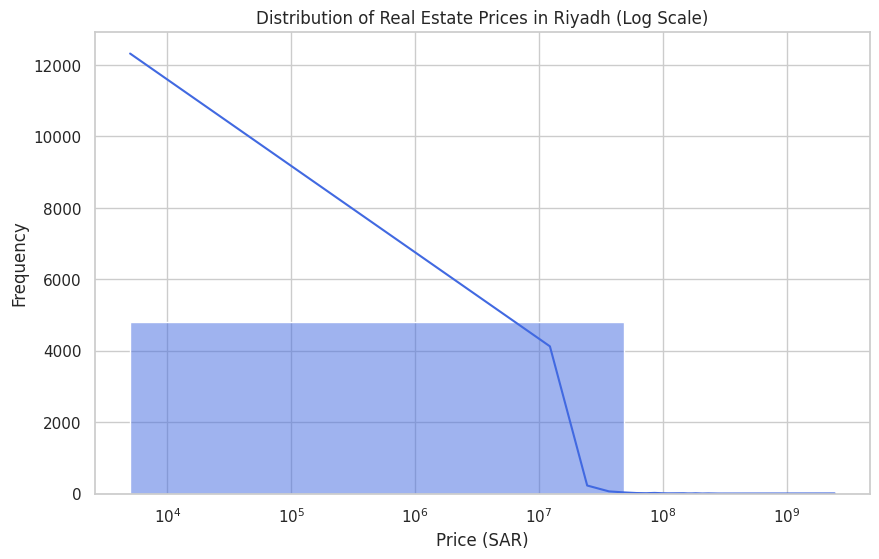

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df_riyadh['السعر'], bins=50, kde=True, color='royalblue')
plt.title('Distribution of Real Estate Prices in Riyadh (Log Scale)')
plt.xlabel('Price (SAR)')
plt.ylabel('Frequency')
plt.xscale('log')
plt.show()

# 4: Visualization - Area vs Price**

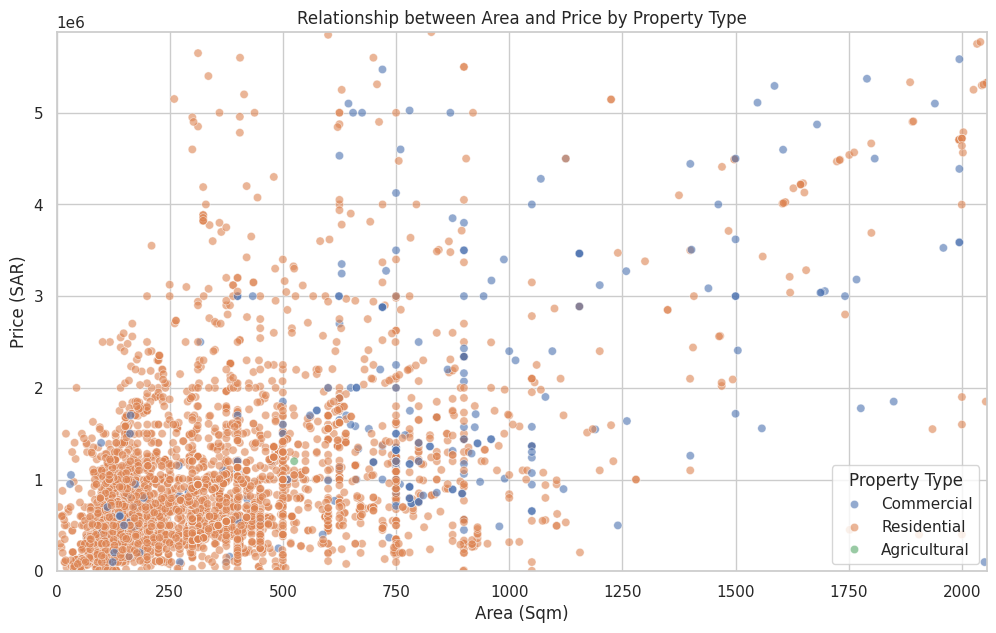

In [ ]:
plt.figure(figsize=(12, 7))
# Using 95th percentile to avoid extreme outliers in the plot
limit_area = df_riyadh['المساحة'].quantile(0.95)
limit_price = df_riyadh['السعر'].quantile(0.95)

sns.scatterplot(data=df_riyadh, x='المساحة', y='السعر', hue='Property_Type', alpha=0.6)
plt.title('Relationship between Area and Price by Property Type')
plt.xlim(0, limit_area)
plt.ylim(0, limit_price)
plt.xlabel('Area (Sqm)')
plt.ylabel('Price (SAR)')
plt.legend(title='Property Type')
plt.show()

# **5: Visualization - Average Price by Category**

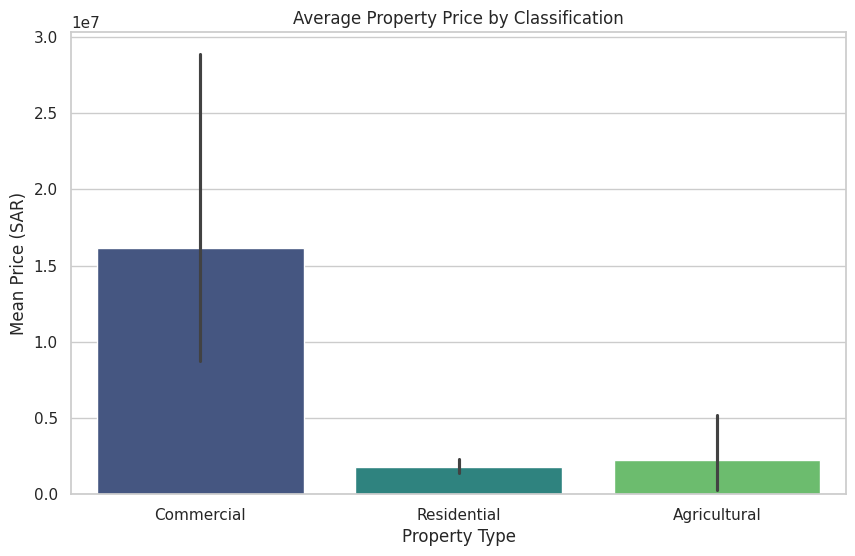

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df_riyadh, x='Property_Type', y='السعر', palette='viridis', estimator=np.mean)
plt.title('Average Property Price by Classification')
plt.xlabel('Property Type')
plt.ylabel('Mean Price (SAR)')
plt.show()

# **6: Visualization - Most Active Districts (Top 10)**

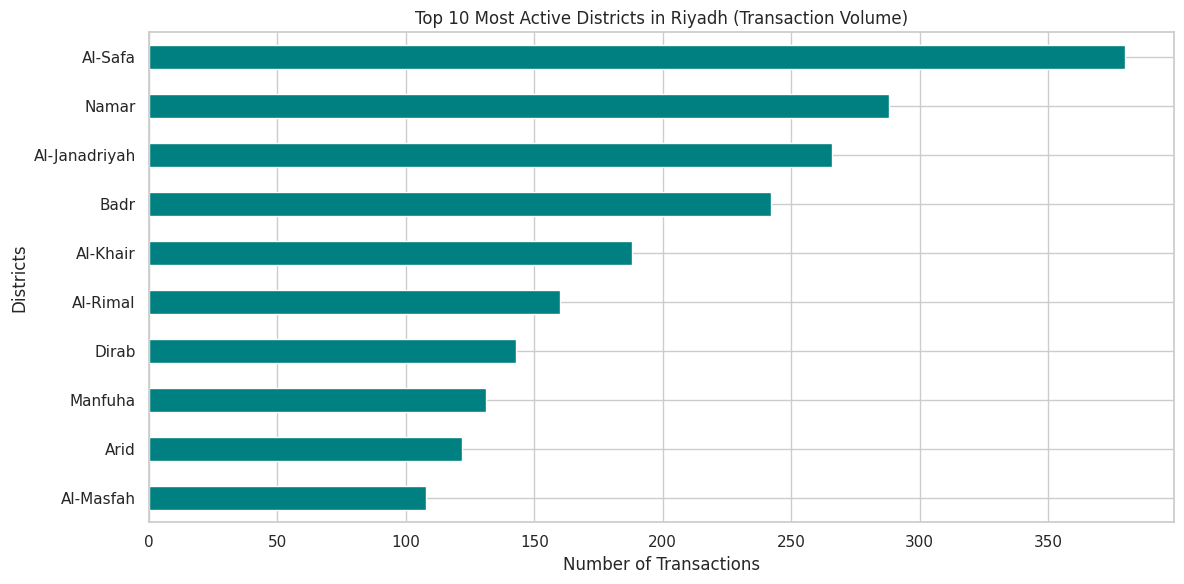

In [ ]:
plt.figure(figsize=(12, 6))

# 1. Define translation map for the Top 10 districts found in Riyadh data
district_map = {
    'الرياض/الصفاء': 'Al-Safa',
    'الرياض/نمار': 'Namar',
    'الرياض/الجنادرية': 'Al-Janadriyah',
    'الرياض/بدر': 'Badr',
    'الرياض/الخير': 'Al-Khair',
    'الرياض/الرمال': 'Al-Rimal',
    'الرياض/ديراب': 'Dirab',
    'الرياض/منفوحة': 'Manfuha',
    'الرياض/عريض': 'Arid',
    'الرياض/المصفاة': 'Al-Masfah'
}

# 2. Get top 10 districts and rename them to English
top_districts = df_riyadh['المدينة / الحي'].value_counts().head(10).rename(index=district_map)

# 3. Plotting (Horizontal Bar Chart)
top_districts.plot(kind='barh', color='teal')

# 4. English Titles and Axis Labels
plt.title('Top 10 Most Active Districts in Riyadh (Transaction Volume)')
plt.xlabel('Number of Transactions')
plt.ylabel('Districts') # Updated label

# Invert axis to show the highest at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

# **7:Visualization - Correlation Matrix**

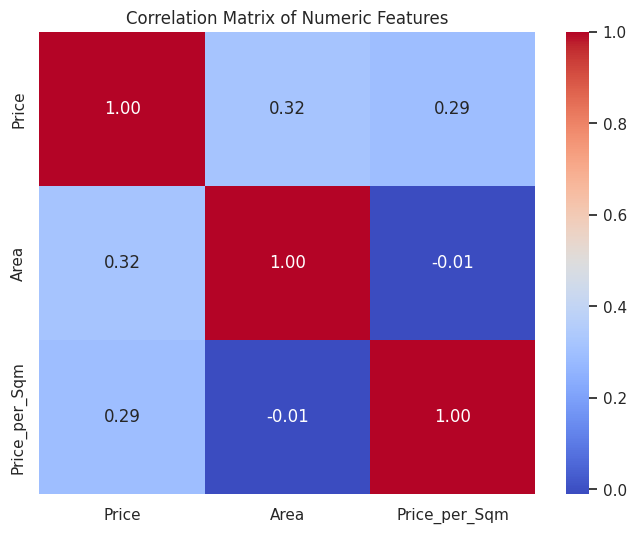

In [ ]:
plt.figure(figsize=(8, 6))
corr_data = df_riyadh[['السعر', 'المساحة', 'Price_per_Sqm']]
corr_data.columns = ['Price', 'Area', 'Price_per_Sqm']
sns.heatmap(corr_data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.show()

# **8: Outlier Removal (The Accuracy Booster)**

In [ ]:
# Remove extreme values to help the model learn better patterns
Q1 = df_riyadh['Price_per_Sqm'].quantile(0.25)
Q3 = df_riyadh['Price_per_Sqm'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df_riyadh[(df_riyadh['Price_per_Sqm'] >= lower_bound) & (df_riyadh['Price_per_Sqm'] <= upper_bound)].copy()

print(f"Outliers removed. Rows kept: {len(df_clean)} (from {len(df_riyadh)})")

Outliers removed. Rows kept: 4490 (from 4828)


# **9: Feature Encoding (District & Type)**

In [ ]:
# Transform text labels into numbers for the ML model
le_district = LabelEncoder()
df_clean['District_Encoded'] = le_district.fit_transform(df_clean['المدينة / الحي'])

le_type = LabelEncoder()
df_clean['Type_Encoded'] = le_type.fit_transform(df_clean['تصنيف العقار'])

# Select features: Area, Property Type, and District
X = df_clean[['المساحة', 'Type_Encoded', 'District_Encoded']]
y = df_clean['السعر']

# 10: Data Splitting (80/20) and Scaling**

In [ ]:
# Split 80% Training / 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features to a standard range
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data splitted and scaled successfully.")

Data splitted and scaled successfully.


# **11: Model Training and Performance Summary**

In [ ]:
# Initialize and Train Models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results_list = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results_list.append({
        'Model Name': name,
        'Avg Error (MAE)': f"{mae:,.2f} SAR",
        'Accuracy %': f"{max(0, r2*100):.2f}%",
        'R2 Score': f"{r2:.4f}"
    })

# Show Comparison Table
results_df = pd.DataFrame(results_list).sort_values(by='R2 Score', ascending=False)
print("\n" + "="*25 + " FINAL SUMMARY " + "="*25)
print(results_df.to_string(index=False))


========================= FINAL SUMMARY =========================
       Model Name  Avg Error (MAE) Accuracy % R2 Score
    Decision Tree   702,809.62 SAR     92.11%   0.9211
    Random Forest   618,109.22 SAR     91.60%   0.9160
Linear Regression 2,233,712.95 SAR     33.74%   0.3374


# **12: Live Prediction Function**

In [ ]:
def predict_price(area, prop_type, district):
    try:
        # Encode inputs using saved encoders
        t_enc = le_type.transform([prop_type])[0]
        d_enc = le_district.transform([district])[0]

        # Scale and Predict using the best model (Random Forest)
        inp = scaler.transform([[area, t_enc, d_enc]])
        price = models["Random Forest"].predict(inp)[0]

        print(f"\nPrediction for {area}m2 {prop_type} in {district}:")
        print(f"Estimated Market Value: {price:,.2f} SAR")
    except:
        print("Error: Please check if the District name exists in the dataset.")

# Example test:
predict_price(area=500, prop_type='سكني', district='الرياض/نمار')


Prediction for 500m2 سكني in الرياض/نمار:
Estimated Market Value: 978,375.02 SAR


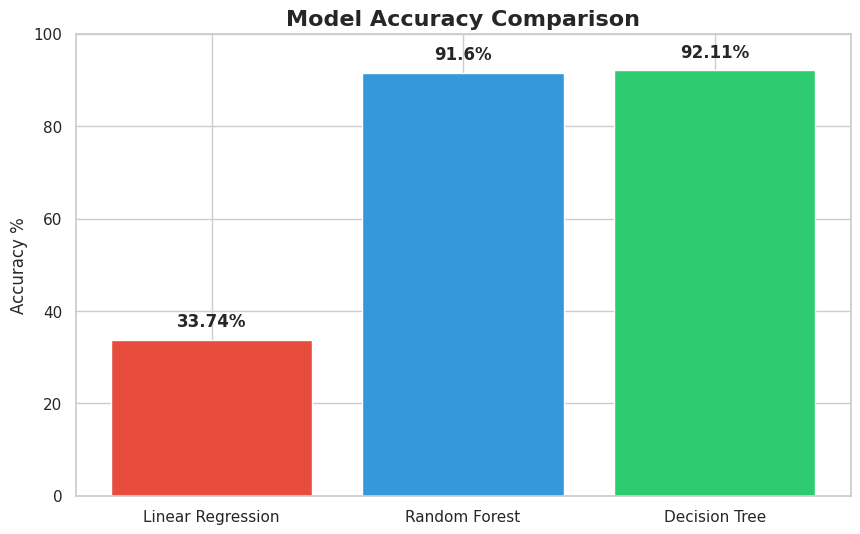

In [ ]:
import matplotlib.pyplot as plt

# Data from your summary
models = ['Linear Regression', 'Random Forest', 'Decision Tree']
accuracy = [33.74, 91.60, 92.11]
colors = ['#e74c3c', '#3498db', '#2ecc71'] # Red, Blue, Green

# Create the plot
plt.figure(figsize=(10, 6))
bars = plt.bar(models, accuracy, color=colors)

# Add titles and labels
plt.title('Model Accuracy Comparison', fontsize=16, fontweight='bold')
plt.ylabel('Accuracy %', fontsize=12)
plt.ylim(0, 100) # Set limit to 100% for perspective

# Add the percentage numbers on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f'{yval}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Save as high-res image
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
